In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
dataset_path = Path("../dataset/raw")

print("Dataset Exists:", dataset_path.exists())

Dataset Exists: True


In [3]:
classes = sorted([
    folder.name
    for folder in dataset_path.iterdir()
    if folder.is_dir()
    and folder.name.startswith("Tomato")
])

print("Total Classes:", len(classes))
print(classes)

Total Classes: 10
['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [4]:
class_name = classes[0]

folder_path = dataset_path / class_name

image_paths = list(folder_path.glob("*.JPG"))

image_path = image_paths[0]

print("Image Path:", image_path)

Image Path: ..\dataset\raw\Tomato_Bacterial_spot\00416648-be6e-4bd4-bc8d-82f43f8a7240___GCREC_Bact.Sp 3110.JPG


In [5]:
image_paths = [
    p for p in folder_path.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

image_path = image_paths[0]

In [6]:
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224),
    color_mode="rgb"
)

print("Image Loaded Successfully")

Image Loaded Successfully


In [7]:
img_array = tf.keras.utils.img_to_array(img)

print("Image Shape:", img_array.shape)

print("Minimum Pixel Value:", img_array.min())

print("Maximum Pixel Value:", img_array.max())

Image Shape: (224, 224, 3)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 176.0


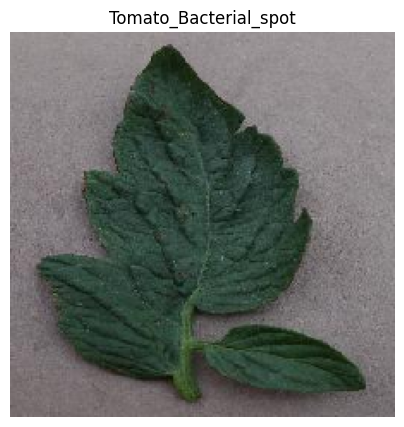

In [8]:
plt.figure(figsize=(5, 5))

plt.imshow(img_array.astype("uint8"))

plt.title(class_name)

plt.axis("off")

plt.show()

In [9]:
print(img_array.shape)
print(img_array.min())
print(img_array.max())

(224, 224, 3)
0.0
176.0


In [10]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

normalized_img = preprocess_input(img_array.copy())

print("Original Min:", img_array.min())
print("Original Max:", img_array.max())

print("Normalized Min:", normalized_img.min())
print("Normalized Max:", normalized_img.max())

Original Min: 0.0
Original Max: 176.0
Normalized Min: -1.0
Normalized Max: 0.3803922


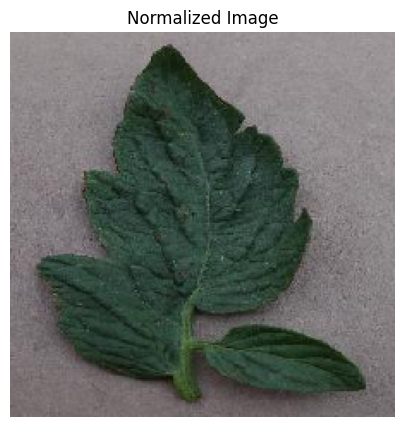

In [11]:
plt.figure(figsize=(5,5))

plt.imshow((normalized_img + 1) / 2)

plt.title("Normalized Image")
plt.axis("off")

plt.show()

In [13]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

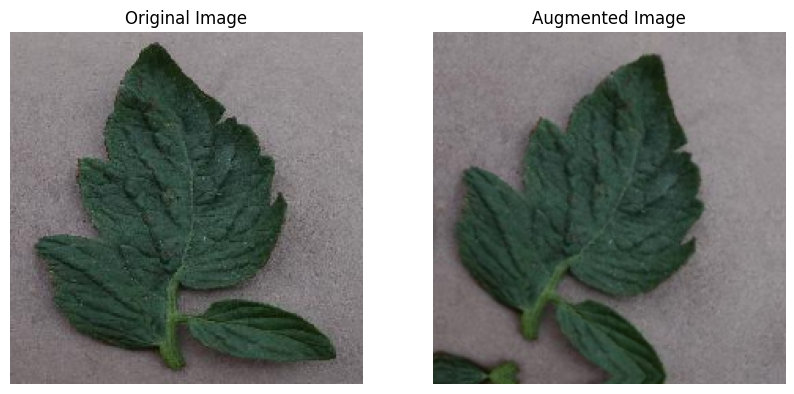

In [14]:
# Original image: (224, 224, 3)
input_image = tf.expand_dims(img_array, axis=0)

# Apply augmentation
augmented_image = data_augmentation(input_image)

# Remove batch dimension
augmented_image = tf.squeeze(augmented_image, axis=0)

# Display
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array.astype("uint8"))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(tf.clip_by_value(augmented_image, 0, 255), tf.uint8))
plt.title("Augmented Image")
plt.axis("off")

plt.show()

In [15]:
dataset_path = "../dataset/raw"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=41,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

temp_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

Found 16011 files belonging to 10 classes.
Using 11208 files for training.
Found 16011 files belonging to 10 classes.
Using 4803 files for validation.


In [16]:
val_batches = tf.data.experimental.cardinality(temp_dataset)

validation_dataset = temp_dataset.take(val_batches // 2)

test_dataset = temp_dataset.skip(val_batches // 2)

In [17]:
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())

print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())

print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

print("Class Names:", train_dataset.class_names)

Training batches: 351
Validation batches: 75
Testing batches: 76
Class Names: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [19]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.shuffle(
    buffer_size=1000,
    seed=42
).prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)